# Mini Project 1 — Comparative Word Frequency Analysis

**Question:** does a writer's word-frequency profile stay recognisably *theirs* across different books, and if so, which part of the vocabulary carries that signal?

### Design

| | Texts |
|---|---|
| **Same author (Jane Austen)** | `austen-emma.txt`, `austen-sense.txt` |
| **Different author (Herman Melville)** | `melville-moby_dick.txt` |

Those three are the core comparison the brief asks for. But a comparison of *one* within-author pair against *one* between-author pair is a sample size of 1 vs 1 — if the within-author distance comes out smaller, we can't tell whether that reflects authorship or just the luck of which two books we picked. So the notebook also runs an **extended set** using every Austen and Chesterton novel in the NLTK corpus:

- Austen: *Emma*, *Sense and Sensibility*, *Persuasion*
- Chesterton: *The Ball and the Cross*, *The Innocence of Father Brown*, *The Man Who Was Thursday*
- Melville: *Moby-Dick*

That gives **6 within-author pairs** and **15 between-author pairs** from the same pool of 7 books, so "within < between" becomes a claim about two distributions rather than two numbers. Hypothesis tests are reported on the extended set; the core three are shown separately throughout.

### Hypotheses

- **H1** — Two books by one author will have more similar frequency profiles than two books by different authors.
- **H2** — The most distinctive words by raw count will be content words tied to plot and setting, telling us more about the *book* than the *author*.
- **H3** — Function-word differences will be smaller in magnitude but more consistent within an author, and therefore the better stylistic signal.

## 0. Setup

In [1]:
import re, math, itertools, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

import nltk
from nltk.corpus import gutenberg

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

# NLTK ships the Gutenberg texts as a downloadable corpus; these are no-ops if already present.
for pkg, check in [("gutenberg", gutenberg.fileids), ("stopwords", None)]:
    try:
        check() if check else __import__("nltk.corpus", fromlist=["stopwords"]).stopwords.words("english")
    except LookupError:
        nltk.download(pkg)

from nltk.corpus import stopwords

print(f"nltk {nltk.__version__} | {len(gutenberg.fileids())} texts available")

nltk 3.10.3 | 18 texts available


In [2]:
CORE = {
    "Emma (Austen)":            "austen-emma.txt",
    "Sense & Sens. (Austen)":   "austen-sense.txt",
    "Moby-Dick (Melville)":     "melville-moby_dick.txt",
}

EXTENDED = {
    **CORE,
    "Persuasion (Austen)":      "austen-persuasion.txt",
    "Ball & Cross (Chesterton)":"chesterton-ball.txt",
    "Father Brown (Chesterton)":"chesterton-brown.txt",
    "Thursday (Chesterton)":    "chesterton-thursday.txt",
}

AUTHOR = {label: fid.split("-")[0].capitalize() for label, fid in EXTENDED.items()}
AUTHOR_COLOR = {"Austen": "#B5432F", "Chesterton": "#2F6FB5", "Melville": "#3F8F5C"}

pd.DataFrame({"file": EXTENDED, "author": AUTHOR}).sort_values("author")

,file,author
Emma (Austen),austen-emma.txt,Austen
Sense & Sens. (Austen),austen-sense.txt,Austen
Persuasion (Austen),austen-persuasion.txt,Austen
Ball & Cross (Chesterton),chesterton-ball.txt,Chesterton
Father Brown (Chesterton),chesterton-brown.txt,Chesterton
Thursday (Chesterton),chesterton-thursday.txt,Chesterton
Moby-Dick (Melville),melville-moby_dick.txt,Melville


## 1. Loading and cleaning

The brief's caveat is the important bit here: Gutenberg plain-text files are wrapped in a licence header and footer, and many also carry front matter (title pages, tables of contents, translator's notes) that isn't the author's prose. If any of that survives into the frequency table, words like *gutenberg*, *ebook* and *copyright* end up looking like stylistic markers.

`clean_text()` handles three layers, in order:

1. **Licence boilerplate** — everything before `*** START OF ... ***` and after `*** END OF ... ***`. NLTK's bundled copies have already had this removed, so these regexes usually match nothing. They're kept anyway so the same function works on files downloaded straight from gutenberg.org.
2. **NLTK's bracketed title line** — the bundled copies open with e.g. `[Emma by Jane Austen 1816]`. Left in, that contributes a spurious count for the author's own name.
3. **Per-text front matter** — *Moby-Dick* opens with the "Etymology" and "Extracts" sections: ~80 quotations *about* whales collected from other writers. That's roughly 20k characters of other people's prose sitting in front of Melville's novel, so we cut to the start of Chapter 1.

The function reports how much it removed so the stripping is auditable rather than silent.

In [3]:
RE_START = re.compile(r"\*\*\*\s*START OF (?:THIS |THE )?PROJECT GUTENBERG.*?\*\*\*", re.I | re.S)
RE_END   = re.compile(r"\*\*\*\s*END OF (?:THIS |THE )?PROJECT GUTENBERG.*?\*\*\*", re.I | re.S)
RE_TITLE = re.compile(r"^\s*\[[^\]]{0,200}\]\s*", re.S)   # NLTK's "[Emma by Jane Austen 1816]" line

# Texts needing extra front matter removed, and the pattern marking where the author's prose starts.
FRONT_MATTER = {"melville-moby_dick.txt": re.compile(r"CHAPTER\s+1\b", re.I)}

def clean_text(fid, verbose=True):
    raw = gutenberg.raw(fid).replace("\r\n", "\n")
    n_raw, notes = len(raw), []

    m = RE_START.search(raw)
    if m:
        raw = raw[m.end():]; notes.append("licence header")
    m = RE_END.search(raw)
    if m:
        raw = raw[:m.start()]; notes.append("licence footer")
    if RE_TITLE.match(raw):
        raw = RE_TITLE.sub("", raw); notes.append("title line")
    if fid in FRONT_MATTER:
        m = FRONT_MATTER[fid].search(raw)
        if m:
            raw = raw[m.start():]; notes.append("front matter")

    if verbose:
        removed = n_raw - len(raw)
        print(f"{fid:26s} {n_raw:>9,} -> {len(raw):>9,} chars "
              f"({removed:>6,} removed, {100*removed/n_raw:4.1f}%)  {', '.join(notes) or 'nothing to strip'}")
    return raw

### Loading from a URL instead

The course notes load texts straight from Project Gutenberg over HTTP. The function below does that, applying the same cleaning pipeline afterwards, and falls back to the bundled NLTK copy if the network is unavailable — which is the situation the notes anticipate when they suggest downloading the file manually.

The rest of the notebook uses the NLTK corpus. It is the same text, it needs no network, and it guarantees that anyone re-running this gets byte-identical results.

In [4]:
GUTENBERG_URLS = {   # the two books used in the course notes
    "Pride and Prejudice": "https://www.gutenberg.org/ebooks/1342.txt.utf-8",
    "Huckleberry Finn":    "https://www.gutenberg.org/ebooks/76.txt.utf-8",
}

def load_from_url(url, timeout=10):
    "Fetch a Gutenberg plain-text file and apply the same boilerplate stripping."
    import requests
    from bs4 import BeautifulSoup
    r = requests.get(url, timeout=timeout)
    r.raise_for_status()
    text = r.text
    if "<html" in text[:500].lower():          # some Gutenberg URLs serve HTML
        text = BeautifulSoup(text, "html.parser").get_text()
    text = text.replace("\r\n", "\n")
    m = RE_START.search(text)
    if m: text = text[m.end():]
    m = RE_END.search(text)
    if m: text = text[:m.start()]
    return text

try:
    sample = load_from_url(GUTENBERG_URLS["Pride and Prejudice"])
    print(f"fetched over HTTP: {len(tokenize(sample)):,} tokens")
except Exception as e:
    print(f"HTTP fetch unavailable ({type(e).__name__}) — using the bundled NLTK corpus instead.")
    print("This is expected in a sandboxed environment and changes nothing downstream.")

HTTP fetch unavailable (HTTPError) — using the bundled NLTK corpus instead.
This is expected in a sandboxed environment and changes nothing downstream.


### Tokenisation

One regex, `[a-z]+(?:'[a-z]+)?`, applied after lowercasing. It keeps alphabetic words and internal apostrophes, and drops punctuation, numerals and anything mixed (`1851`, `--`, `&`) by simply never matching them.

Keeping the apostrophe matters for a frequency study: splitting on it would turn *Elinor's* into `elinor` + `s`, inflating the count of the character's name and inventing a phantom high-frequency token `s`. The cost is that possessives and contractions are counted as their own types, which slightly raises vocabulary size. That's the better trade here — it's consistent across all seven texts, so it can't bias the comparison in either direction.

In [5]:
RE_WORD = re.compile(r"[a-z]+(?:'[a-z]+)?")

def tokenize(text):
    return RE_WORD.findall(text.lower())

tokens, counts = {}, {}
for label, fid in EXTENDED.items():
    tk = tokenize(clean_text(fid))
    tokens[label], counts[label] = tk, Counter(tk)

print()
print("Sanity check — do any boilerplate markers survive into the token stream?")
for w in ["gutenberg", "ebook", "copyright", "transcriber", "proofreading", "etymology"]:
    hits = {lab: c[w] for lab, c in counts.items() if c[w]}
    print(f"  {w:13s} {hits if hits else 'absent from all texts'}")

austen-emma.txt              887,071 ->   887,043 chars (    28 removed,  0.0%)  title line


austen-sense.txt             673,022 ->   672,977 chars (    45 removed,  0.0%)  title line
melville-moby_dick.txt     1,220,066 -> 1,198,622 chars (21,444 removed,  1.8%)  title line, front matter


austen-persuasion.txt        466,292 ->   466,257 chars (    35 removed,  0.0%)  title line
chesterton-ball.txt          457,450 ->   444,004 chars (13,446 removed,  2.9%)  licence footer, title line


chesterton-brown.txt         406,629 ->   406,573 chars (    56 removed,  0.0%)  title line
chesterton-thursday.txt      320,525 ->   320,472 chars (    53 removed,  0.0%)  title line

Sanity check — do any boilerplate markers survive into the token stream?
  gutenberg     absent from all texts
  ebook         absent from all texts
  copyright     absent from all texts
  transcriber   absent from all texts
  proofreading  absent from all texts
  etymology     absent from all texts


## 2. Descriptive statistics

**A warning about type–token ratio.** TTR (vocabulary size ÷ token count) is not comparable across texts of different lengths. Every text reuses common words as it goes, so TTR falls monotonically as a text gets longer — a long book will score lower than a short one even if the author's vocabulary is identical. Since *Moby-Dick* is 2.5× the length of *Persuasion*, raw TTR would be measuring length as much as lexical richness.

So the table reports TTR (because the brief asks for it) alongside **MSTTR-1000**: the text is cut into consecutive 1,000-token windows, TTR is computed in each, and the results averaged. Every text is then measured on the same denominator. Watch how the two columns disagree.

In [6]:
def msttr(tk, window=1000):
    segs = [tk[i:i+window] for i in range(0, len(tk) - window + 1, window)]
    return float(np.mean([len(set(s)) / window for s in segs]))

desc = pd.DataFrame([{
    "author":     AUTHOR[lab],
    "tokens":     len(tokens[lab]),
    "types":      len(counts[lab]),
    "TTR":        len(counts[lab]) / len(tokens[lab]),
    "MSTTR-1000": msttr(tokens[lab]),
    "hapax %":    100 * sum(1 for c in counts[lab].values() if c == 1) / len(counts[lab]),
} for lab in EXTENDED], index=list(EXTENDED)).sort_values("tokens", ascending=False)

display(desc.style.format({"tokens": "{:,.0f}", "types": "{:,.0f}", "TTR": "{:.4f}",
                           "MSTTR-1000": "{:.4f}", "hapax %": "{:.1f}"}))

r = np.corrcoef(desc["tokens"], desc["TTR"])[0, 1]
print(f"correlation between length and raw TTR:  r = {r:+.2f}   <- TTR is tracking length")
print(f"correlation between length and MSTTR:    r = {np.corrcoef(desc['tokens'], desc['MSTTR-1000'])[0,1]:+.2f}")

,author,tokens,types,TTR,MSTTR-1000,hapax %
Moby-Dick (Melville),Melville,"212,327","17,091",0.0805,0.4692,44.0
Emma (Austen),Austen,"160,990","7,203",0.0447,0.3980,38.9
Sense & Sens. (Austen),Austen,"119,906","6,376",0.0532,0.4103,38.2
Persuasion (Austen),Austen,"83,612","5,822",0.0696,0.4132,43.6
Ball & Cross (Chesterton),Chesterton,"80,058","7,974",0.0996,0.4315,48.5
Father Brown (Chesterton),Chesterton,"72,380","7,880",0.1089,0.4440,48.8
Thursday (Chesterton),Chesterton,"58,286","6,361",0.1091,0.4307,49.0


correlation between length and raw TTR:  r = -0.56   <- TTR is tracking length
correlation between length and MSTTR:    r = +0.26


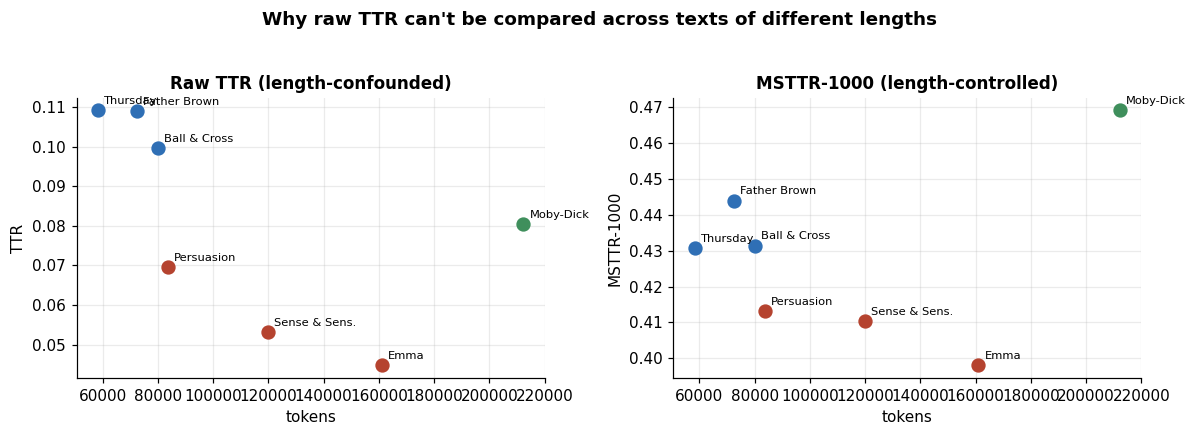

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, title in zip(axes, ["TTR", "MSTTR-1000"],
                          ["Raw TTR (length-confounded)", "MSTTR-1000 (length-controlled)"]):
    for lab in desc.index:
        ax.scatter(desc.loc[lab, "tokens"], desc.loc[lab, col],
                   color=AUTHOR_COLOR[AUTHOR[lab]], s=70, zorder=3)
        ax.annotate(lab.split(" (")[0], (desc.loc[lab, "tokens"], desc.loc[lab, col]),
                    fontsize=7.5, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("tokens"); ax.set_ylabel(col); ax.set_title(title)
fig.suptitle("Why raw TTR can't be compared across texts of different lengths", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

Raw TTR ranks *Emma* as the least lexically varied of the seven and *Father Brown* as among the most — but that ordering is almost entirely a length artefact (note the strong negative correlation with token count). Once the window is fixed at 1,000 tokens the picture changes: the three Austen novels cluster at the bottom, the three Chesterton novels sit higher, and *Moby-Dick* is clearly the richest. That is a real difference and it survives the length control, so it's the version worth interpreting.

Note also that the length-controlled ranking groups the books **by author** — an early hint at H1, arriving from a completely different direction than the frequency comparisons below.

### Top 25 words per text

In [8]:
def relfreq(counter, vocab, per=10_000):
    "Relative frequency per `per` tokens, aligned to `vocab`."
    n = sum(counter.values())
    return np.array([per * counter[w] / n for w in vocab])

def top_table(labels, n=25):
    cols = {}
    for lab in labels:
        total = len(tokens[lab])
        cols[lab] = [f"{w}  {10_000*c/total:,.0f}" for w, c in counts[lab].most_common(n)]
    return pd.DataFrame(cols, index=range(1, n + 1))

print("word and its rate per 10,000 tokens\n")
display(top_table(list(CORE)))

word and its rate per 10,000 tokens



,Emma (Austen),Sense & Sens. (Austen),Moby-Dick (Melville)
1,to 326,to 343,the 668
2,the 323,the 342,of 305
3,and 304,of 298,and 298
4,of 267,and 291,a 218
5,i 198,her 212,to 214
6,a 194,a 174,in 192
7,it 157,i 167,that 139
8,her 154,in 165,his 118
9,was 149,was 155,it 113
10,she 147,it 146,i 93


Two things stand out before any statistics.

**The lists are mostly the same words.** Both Austen novels and *Moby-Dick* are dominated by *the, of, and, a, to, in* — the function-word core that any English text shares. The interesting variation is in the *rates*, not the membership.

**The rates differ sharply, and in a patterned way.** `the` runs at 667 per 10k in *Moby-Dick* against ~320–340 in Austen — roughly double. Meanwhile `she` and `her` are everywhere in Austen and nearly absent from Melville; `i` and `you` are far commoner in Austen. None of this is about vocabulary size. It reflects what the sentences are *doing*: Austen's novels are built from dialogue and free indirect discourse centred on women, Melville's from dense noun-phrase description of objects and cetology. Those are exactly the "syntax habits" H3 predicts will carry the stylistic signal.

Also note `mr` and `mrs` appearing high in Austen. They behave like function words — honorifics attached to nearly every character reference — and they'll show up repeatedly below.

### Content words only — the course's stop-word view

The top-25 lists above are almost entirely function words, which is what makes them useful for H3 but useless for seeing what each book is *about*. Removing stop words before counting — the approach in the course notes — flips this: it strips the grammar and leaves the subject matter.

This is the view the course notes build, and it answers the assignment's third question — "are there words one author prefers?" — directly. It also goes wrong in an instructive way, so it's worth reading the bars carefully rather than just noting that they differ.

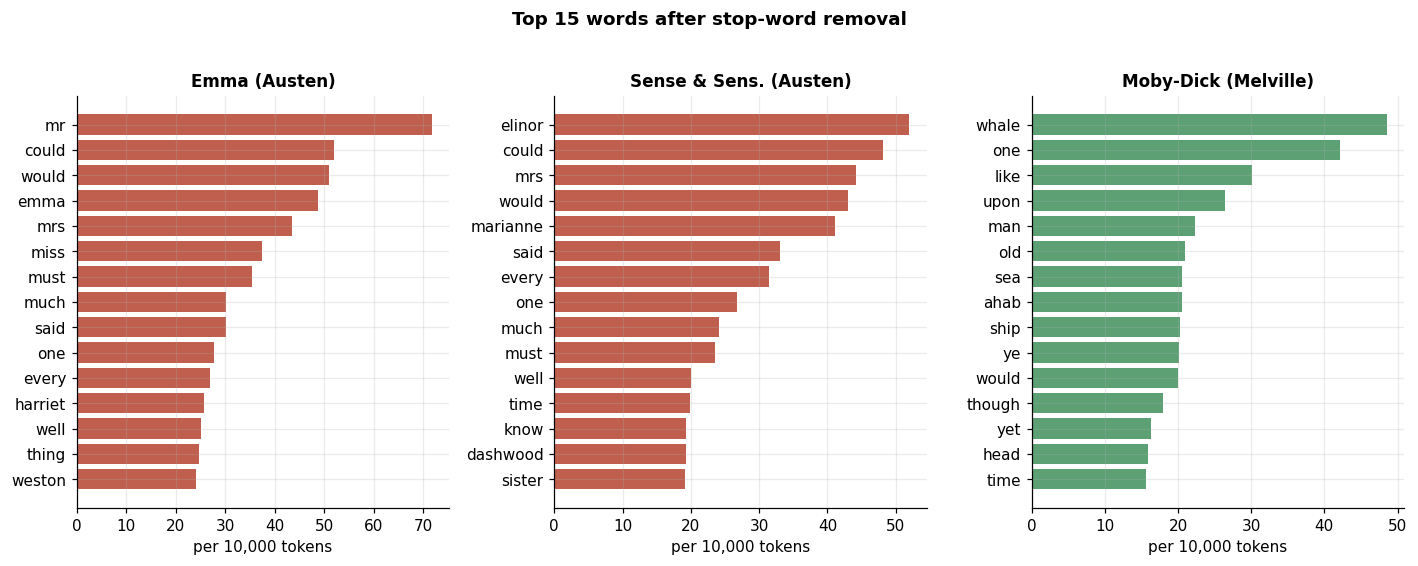

Overlap of these top-15 'content' lists:
  Emma                   / Sense & Sens.           9/15   shared: ['could', 'every', 'mrs', 'much', 'must', 'one', 'said', 'well', 'would']
  Emma                   / Moby-Dick               2/15   shared: ['one', 'would']
  Sense & Sens.          / Moby-Dick               3/15   shared: ['one', 'time', 'would']

Composition of each top-15 list:
  Emma (Austen)            9/15 are function-like words the stop-list missed: ['could', 'every', 'much', 'must', 'one', 'said', 'thing', 'well', 'would']
  Sense & Sens. (Austen)   10/15 are function-like words the stop-list missed: ['could', 'every', 'know', 'much', 'must', 'one', 'said', 'time', 'well', 'would']
  Moby-Dick (Melville)     9/15 are function-like words the stop-list missed: ['like', 'man', 'old', 'one', 'though', 'time', 'upon', 'would', 'yet']


In [9]:
STOP = set(stopwords.words("english"))     # as in the course notes

def top_content(lab, n=15):
    per10k = 10_000 / len(tokens[lab])
    ranked = [(w, c * per10k) for w, c in counts[lab].most_common() if w not in STOP][:n]
    return ranked[::-1]          # reversed: barh draws from the bottom up

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, lab in zip(axes, CORE):
    pairs = top_content(lab)
    ax.barh(range(len(pairs)), [v for _, v in pairs],
            color=AUTHOR_COLOR[AUTHOR[lab]], alpha=0.85)
    ax.set_yticks(range(len(pairs))); ax.set_yticklabels([w for w, _ in pairs])
    ax.set_xlabel("per 10,000 tokens"); ax.set_title(lab)
fig.suptitle("Top 15 words after stop-word removal", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

print("Overlap of these top-15 'content' lists:")
for a, b in itertools.combinations(CORE, 2):
    A = {w for w, _ in top_content(a)}; B = {w for w, _ in top_content(b)}
    print(f"  {a.split(' (')[0]:22s} / {b.split(' (')[0]:22s}  {len(A & B)}/15   shared: {sorted(A & B)}")

# How much of each list is actually about the book, rather than grammar the stop-list missed?
LEAKED = {"could", "would", "must", "much", "one", "said", "well", "every", "upon",
          "though", "yet", "like", "time", "thing", "know", "old", "man"}
print("\nComposition of each top-15 list:")
for lab in CORE:
    ws = [w for w, _ in top_content(lab)]
    leak = [w for w in ws if w in LEAKED]
    print(f"  {lab:24s} {len(leak)}/15 are function-like words the stop-list missed: {sorted(leak)}")

The overlap counts look like a clean win for this method: the two Austen novels share 9 of 15, against 2 and 3 for the Austen/Melville pairings. Stop-word removal appears to have detected authorship.

**It hasn't, and the shared words give it away.** The nine are *could*, *every*, *much*, *must*, *one*, *said*, *well*, *would* and *mrs*. Not one is a content word. They are modals, quantifiers and an honorific that NLTK's stop-list — built for modern text — simply fails to catch. The same leak runs through the *Moby-Dick* panel from the other side: *upon*, *though*, *yet*, *like*, *one* are not whaling vocabulary.

So the bars are measuring two different things stacked on top of each other:

- **Genuine content words**, which are disjoint in *every* pairing, including Austen against Austen: *emma*, *harriet*, *weston* against *elinor*, *marianne*, *dashwood* against *whale*, *ahab*, *ship*, *sea*. Nothing here is shared by any two of the three books. This is H2 exactly — content words identify the book, never the author.
- **Function words that escaped the filter**, which is where the entire 9/15 Austen overlap comes from. *would* runs at 51 and 43 per 10k in the two Austen novels against 20 in *Moby-Dick*; *could* at 52 and 48 against 10.

The irony is worth sitting with. This view was supposed to show subject matter, and its one apparent success at identifying an author comes entirely from the grammatical words it was trying to throw away. That is H3 arriving uninvited, through a hole in the stop-list — and `would`, the word doing much of the work here, is the one the extra credit asks about in section 5.

## 3. Comparing pairs of texts

### 3.1 Overlap of top-N word lists

The crudest comparison: of each text's N most frequent words, what fraction appear in the other's top N? Cheap and assumption-free, but it ignores rates entirely — a word at rank 3 and the same word at rank 97 both just count as "present".

In [10]:
def top_overlap(a, b, n):
    A = {w for w, _ in counts[a].most_common(n)}
    B = {w for w, _ in counts[b].most_common(n)}
    return len(A & B) / n

def pair_kind(a, b):
    return "within-author" if AUTHOR[a] == AUTHOR[b] else "between-author"

PAIRS = list(itertools.combinations(EXTENDED, 2))
NS = [25, 100, 500, 1000]

overlap = pd.DataFrame([
    {"pair": f"{a.split(' (')[0]} / {b.split(' (')[0]}", "kind": pair_kind(a, b),
     **{f"top-{n}": top_overlap(a, b, n) for n in NS}}
    for a, b in PAIRS
])

print("CORE THREE")
core_mask = overlap["pair"].isin(["Emma / Sense & Sens.", "Emma / Moby-Dick", "Sense & Sens. / Moby-Dick"])
display(overlap[core_mask].style.format({f"top-{n}": "{:.1%}" for n in NS}).hide(axis="index"))

print("\nEXTENDED SET — mean overlap by pair type")
display(overlap.groupby("kind")[[f"top-{n}" for n in NS]].mean()
        .style.format("{:.1%}"))

CORE THREE


pair,kind,top-25,top-100,top-500,top-1000
Emma / Sense & Sens.,within-author,92.0%,86.0%,80.0%,74.8%
Emma / Moby-Dick,between-author,68.0%,65.0%,54.8%,48.2%
Sense & Sens. / Moby-Dick,between-author,76.0%,68.0%,55.6%,47.1%



EXTENDED SET — mean overlap by pair type


,top-25,top-100,top-500,top-1000
kind,,,,
between-author,78.1%,70.1%,59.4%,51.4%
within-author,92.7%,85.5%,76.9%,71.7%


The separation is already visible and it **widens as N grows**. At the top 25 the gap is modest — everyone uses *the* and *of* — but by the top 1,000 within-author pairs share about 72% of their list against 51% for between-author pairs. That makes sense: the top 25 is nearly universal English, while ranks 100–1,000 are where an author's habitual mid-frequency vocabulary lives.

Useful as a first pass, but it can't distinguish a word used twice as often from one used 1% more often. Everything below uses rates.

### 3.2 Scatter plots of relative frequency

Each point is a word: its rate in text A against its rate in text B, both per 10,000 tokens, on log–log axes. Log scaling is essential — word frequencies span five orders of magnitude, so on linear axes `the` would sit alone in a corner and the other 10,000 words would pile up at the origin.

The diagonal is "used at the same rate in both". Points off it are used more in one text than the other; distance from the diagonal is the size of the difference.

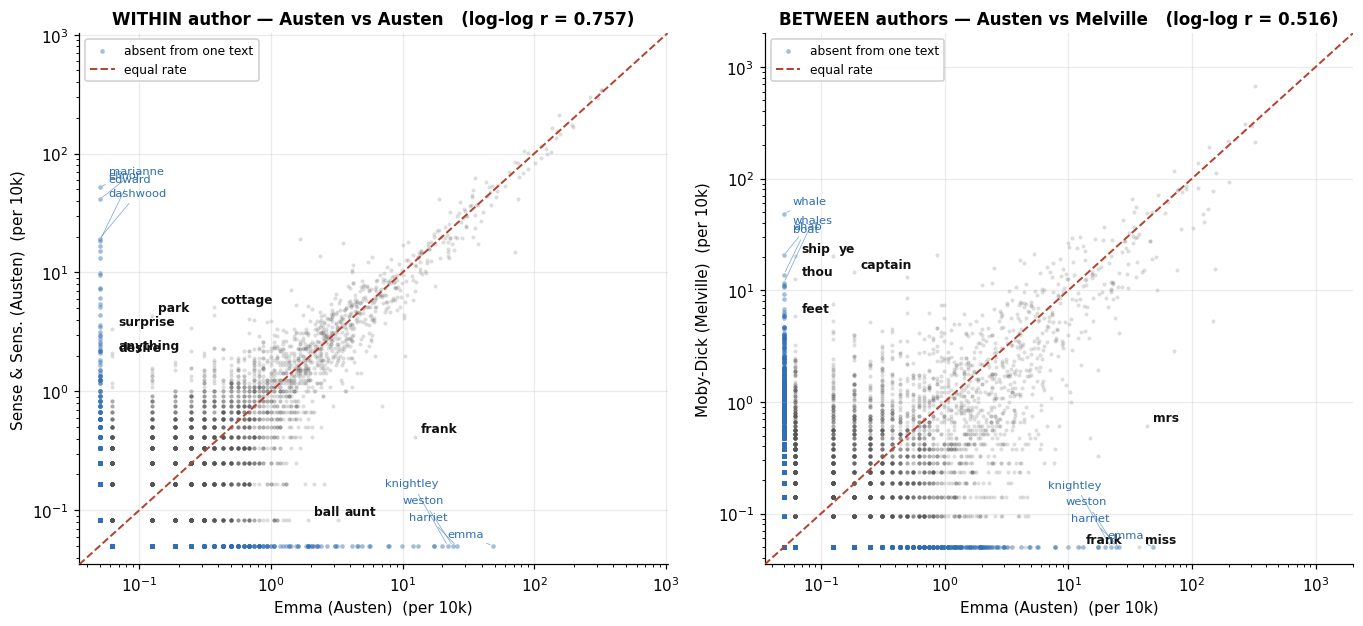

In [11]:
def scatter_pair(ax, a, b, floor=0.05):
    vocab = np.array(sorted(set(counts[a]) | set(counts[b])))
    fa, fb = relfreq(counts[a], vocab), relfreq(counts[b], vocab)
    # a word absent from one text has log(0); pin those to a floor below the visible range
    x, y = np.maximum(fa, floor), np.maximum(fb, floor)
    shared = (fa > 0) & (fb > 0)

    ax.scatter(x[shared], y[shared], s=7, alpha=0.20, color="#555555", linewidths=0)
    ax.scatter(x[~shared], y[~shared], s=9, alpha=0.45, color="#2F6FB5", linewidths=0,
               label="absent from one text")
    lims = [floor * 0.7, max(x.max(), y.max()) * 3]
    ax.plot(lims, lims, color="#B5432F", lw=1.3, ls="--", zorder=4, label="equal rate")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel(f"{a}  (per 10k)"); ax.set_ylabel(f"{b}  (per 10k)")

    # (1) words used by BOTH but at very different rates - labelled in place
    dev = np.abs(np.log2((fa + 0.05) / (fb + 0.05))) * (shared & ((fa + fb) > 2.0))
    for i in np.argsort(dev)[-8:]:
        ax.annotate(vocab[i], (x[i], y[i]), fontsize=8, fontweight="bold", color="#111111",
                    xytext=(4, 3), textcoords="offset points", zorder=6)

    # (2) words exclusive to one text - all sit on the floor line, so stagger the labels
    for mask, rate, ha in [(~shared & (fb == 0), fa, "right"), (~shared & (fa == 0), fb, "left")]:
        top = np.argsort(rate * mask)[-4:][::-1]
        for rank, i in enumerate(top):
            ax.annotate(vocab[i], (x[i], y[i]), fontsize=7.5, color="#2F6FB5", ha=ha,
                        xytext=(-6 if ha == "right" else 6, 6 + rank * 11),
                        textcoords="offset points", zorder=6,
                        arrowprops=dict(arrowstyle="-", lw=0.5, color="#2F6FB5", alpha=0.6))
    ax.legend(loc="upper left", fontsize=8, framealpha=0.95)
    return np.corrcoef(np.log10(x), np.log10(y))[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.8))
r1 = scatter_pair(axes[0], "Emma (Austen)", "Sense & Sens. (Austen)")
axes[0].set_title(f"WITHIN author — Austen vs Austen   (log-log r = {r1:.3f})")
r2 = scatter_pair(axes[1], "Emma (Austen)", "Moby-Dick (Melville)")
axes[1].set_title(f"BETWEEN authors — Austen vs Melville   (log-log r = {r2:.3f})")
plt.tight_layout(); plt.show()

The two panels differ in exactly the way H1 predicts, and the difference is structural rather than a matter of degree.

**Within Austen (left):** a tight cloud hugging the diagonal, and the log-log correlation is high (r = 0.76). Almost every outlier is a blue floor point — a word in one novel and absent from the other — and they are character and place names: *Emma*, *Knightley*, *Weston*, *Harriet* on one side; *Marianne*, *Edward*, *Dashwood* on the other. Strip the proper nouns and the two novels are nearly the same text statistically.

**Between authors (right):** the cloud is far more scattered (r = 0.52), and crucially the spread persists *into the high-frequency region at the top right*, where names never reach. The whole upper cloud is tilted off the diagonal. `the` is the extreme case — top right, well above the line, at 668 per 10k in *Moby-Dick* against 323 in *Emma* — and `she` and `her` sit equally far below it. Those are words both authors use constantly; they simply use them at different rates.

The labelled mid-frequency words make the same point in miniature. *ship*, *ye*, *thou*, *captain*, *feet* versus *mrs*, *miss*: partly subject matter, but *ye* and *thou* are pure register, not plot.

That distinction is the heart of the project. Within an author, differences live at the bottom-left — rare, book-specific words. Between authors, differences appear at the top-right too, in the common vocabulary. The second kind is what stylometry is built on.

### 3.3 Distance measures

Overlaps and scatter plots are visual. To rank pairs we need one number each. Two measures, over the union vocabulary of each pair (a word missing from one text counts as rate 0):

- **Cosine similarity** — the angle between the two relative-frequency vectors, in [0, 1]; 1 is identical. Because it works on raw rates, it is dominated by the largest components, so in practice it is mostly a comparison of the top few dozen words.
- **Jensen–Shannon divergence** — a symmetric, bounded measure of how far apart two probability distributions are. Reported here as JS *distance* (the square root of the divergence, in bits), which is a true metric. 0 is identical; larger is more different. It's sensitive across the whole distribution, not just the head.

Each is computed twice: once over the full union vocabulary, and once restricted to **function words only**, which is the direct test of H3.

**Defining "function word" matters more than it looks.** The obvious shortcut is to take the N most frequent words in the pooled corpus and call them function words. That shortcut is broken here, and the next cell shows why: because *Moby-Dick* is the longest text in the corpus, `whale` is frequent enough in the pool to make the cut, along with `emma`, `elinor`, `sea` and `ship`. Testing "is the signal content-free?" on a list that smuggles in the single most topic-laden word in the corpus would make H3 unfalsifiable.

So the function-word set is NLTK's English stop-list instead: a fixed, externally curated inventory of articles, pronouns, prepositions, conjunctions, auxiliaries and negations. It was not derived from these texts, so it cannot have been contaminated by them.

This is the same list section 2.4 *discarded* to get at subject matter. Here we discard everything else and keep only the list. The two views use the same partition of the vocabulary and ask opposite questions of it.

In [12]:
pooled = Counter()
for lab in EXTENDED:
    pooled.update(counts[lab])

TOPICAL = {"whale", "whales", "ahab", "queequeg", "emma", "elinor", "marianne",
           "harriet", "ship", "sea", "captain", "boat"}

naive = [w for w, _ in pooled.most_common(200)]
print("NAIVE approach — top 200 words of the pooled corpus.")
print("  content words that sneak in:", sorted(set(naive) & TOPICAL))
print("  -> unusable as a 'content-free' test set\n")

# Curated, external, and not derived from these texts.
FUNCTION_WORDS = sorted({w for w in stopwords.words("english") if RE_WORD.fullmatch(w)}
                        & set(pooled))
print(f"ADOPTED — NLTK English stop-list, {len(FUNCTION_WORDS)} words present in this corpus.")
print("  content words that sneak in:", sorted(set(FUNCTION_WORDS) & TOPICAL) or "none")
print()
print(" ".join(FUNCTION_WORDS))

NAIVE approach — top 200 words of the pooled corpus.
  content words that sneak in: ['captain', 'elinor', 'emma', 'marianne', 'sea', 'ship', 'whale']
  -> unusable as a 'content-free' test set

ADOPTED — NLTK English stop-list, 175 words present in this corpus.
  content words that sneak in: none

a about above after again against all am an and any are aren't as at be because been before being below between both but by can couldn't d did didn't do does doesn't doing don don't down during each few for from further had hadn't has hasn't have haven haven't having he he'd he'll he's her here hers herself him himself his how i i'd i'll i'm i've if in into is isn't it it'll it's its itself just m ma me more most mustn't my myself no nor not now o of off on once only or other our ours ourselves out over own re s same shan't she she'd she's should shouldn't so some such t than that that'll the their theirs them themselves then there these they they'd they'll they're they've this those through 

In [13]:
def cosine(u, v):
    return float(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)))

def js_distance(u, v):
    "Square root of Jensen-Shannon divergence (base 2). A metric, in [0, 1]."
    p, q = u / u.sum(), v / v.sum()
    m = (p + q) / 2
    def kl(x, y):
        nz = x > 0
        return float(np.sum(x[nz] * np.log2(x[nz] / y[nz])))
    return math.sqrt(max(0.0, 0.5 * kl(p, m) + 0.5 * kl(q, m)))

def compare(a, b, vocab=None):
    if vocab is None:
        vocab = sorted(set(counts[a]) | set(counts[b]))
    u, v = relfreq(counts[a], vocab), relfreq(counts[b], vocab)
    return cosine(u, v), js_distance(u, v)

rows = []
for a, b in PAIRS:
    c_all, j_all = compare(a, b)
    c_fw,  j_fw  = compare(a, b, FUNCTION_WORDS)
    rows.append({"text A": a, "text B": b, "kind": pair_kind(a, b),
                 "cosine (all)": c_all, "JS dist (all)": j_all,
                 "cosine (fn words)": c_fw, "JS dist (fn words)": j_fw,
                 "top-1000 overlap": top_overlap(a, b, 1000)})

dist = pd.DataFrame(rows)
METRICS = ["cosine (all)", "JS dist (all)", "cosine (fn words)", "JS dist (fn words)"]

print("ALL 21 PAIRS, sorted by JS distance over function words (most similar first)")
display(dist.sort_values("JS dist (fn words)")
        .assign(**{"text A": lambda d: d["text A"].str.split(" \\(").str[0],
                   "text B": lambda d: d["text B"].str.split(" \\(").str[0]})
        .style.format({m: "{:.4f}" for m in METRICS} | {"top-1000 overlap": "{:.1%}"})
        .background_gradient(cmap="RdYlGn_r", subset=["JS dist (fn words)"])
        .hide(axis="index"))

ALL 21 PAIRS, sorted by JS distance over function words (most similar first)


text A,text B,kind,cosine (all),JS dist (all),cosine (fn words),JS dist (fn words),top-1000 overlap
Ball & Cross,Thursday,within-author,0.9863,0.3461,0.9963,0.0750,71.6%
Emma,Sense & Sens.,within-author,0.9776,0.2992,0.9895,0.0883,74.8%
Ball & Cross,Father Brown,within-author,0.9866,0.3582,0.9941,0.0913,68.0%
Sense & Sens.,Persuasion,within-author,0.9765,0.3122,0.9870,0.0940,73.6%
Emma,Persuasion,within-author,0.9732,0.3067,0.9847,0.0974,76.2%
Father Brown,Thursday,within-author,0.9865,0.3736,0.9952,0.1031,66.1%
Moby-Dick,Ball & Cross,between-author,0.9695,0.4323,0.9817,0.1381,56.9%
Moby-Dick,Father Brown,between-author,0.9712,0.4396,0.9804,0.1449,55.6%
Moby-Dick,Thursday,between-author,0.9627,0.4517,0.9765,0.1507,55.6%
Persuasion,Ball & Cross,between-author,0.9036,0.4714,0.9199,0.2337,51.7%


Every one of the six within-author pairs sorts above every one of the fifteen between-author pairs. No exceptions, no ties. Here is the same result summarised, and the core three extracted:

In [14]:
print("CORE THREE TEXTS — the comparison the brief asks for")
core_pairs = dist[dist["text A"].isin(CORE) & dist["text B"].isin(CORE)]
display(core_pairs.assign(pair=lambda d: d["text A"].str.split(" \\(").str[0] + "  vs  "
                                       + d["text B"].str.split(" \\(").str[0])
        [["pair", "kind"] + METRICS]
        .style.format({m: "{:.4f}" for m in METRICS}).hide(axis="index"))

print("\nEXTENDED SET — distribution of each metric by pair type")
summary = dist.groupby("kind")[METRICS].agg(["mean", "min", "max"]).round(4)
display(summary)

CORE THREE TEXTS — the comparison the brief asks for


pair,kind,cosine (all),JS dist (all),cosine (fn words),JS dist (fn words)
Emma vs Sense & Sens.,within-author,0.9776,0.2992,0.9895,0.0883
Emma vs Moby-Dick,between-author,0.8466,0.5021,0.8626,0.2679
Sense & Sens. vs Moby-Dick,between-author,0.8606,0.5013,0.8734,0.2524



EXTENDED SET — distribution of each metric by pair type


cosine (all)                 JS dist (all)                 cosine (fn words)                 JS dist (fn words)                
                       mean     min     max          mean     min     max              mean     min     max               mean     min     max
kind                                                                                                                                          
between-author       0.8935  0.8466  0.9712        0.4741  0.4323  0.5021            0.9078  0.8626  0.9817             0.2306  0.1381  0.2689
within-author        0.9811  0.9732  0.9866        0.3327  0.2992  0.3736            0.9911  0.9847  0.9963             0.0915  0.0750  0.1031

In [15]:
# Does each metric fully separate the two groups? Margin = gap between the worst
# within-author pair and the best between-author pair. Positive = clean separation.
print(f"{'metric':22s} {'within':>9s} {'between':>9s} {'margin':>9s}   verdict")
print("-" * 68)
for m in METRICS + ["top-1000 overlap"]:
    w = dist[dist.kind == "within-author"][m]
    b = dist[dist.kind == "between-author"][m]
    higher_is_similar = not m.startswith("JS")
    margin = (w.min() - b.max()) if higher_is_similar else (b.min() - w.max())
    print(f"{m:22s} {w.mean():9.4f} {b.mean():9.4f} {margin:+9.4f}   "
          f"{'clean separation' if margin > 0 else 'GROUPS OVERLAP'}")

metric                    within   between    margin   verdict
--------------------------------------------------------------------
cosine (all)              0.9811    0.8935   +0.0020   clean separation
JS dist (all)             0.3327    0.4741   +0.0587   clean separation
cosine (fn words)         0.9911    0.9078   +0.0030   clean separation
JS dist (fn words)        0.0915    0.2306   +0.0350   clean separation
top-1000 overlap          0.7172    0.5145   +0.0920   clean separation


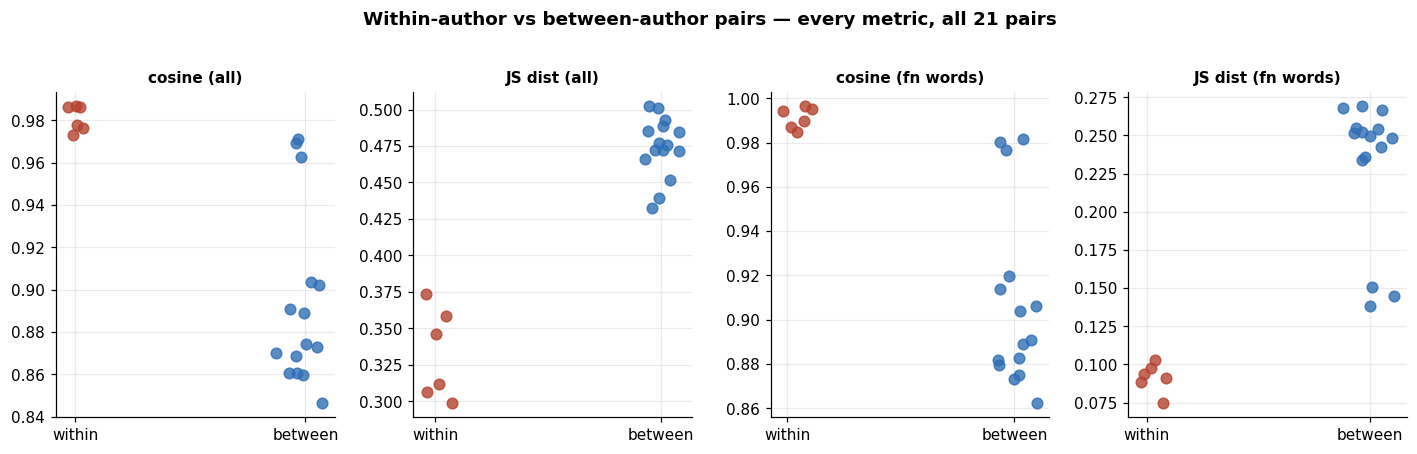

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
rng = np.random.default_rng(0)
for ax, m in zip(axes, METRICS):
    for i, kind in enumerate(["within-author", "between-author"]):
        vals = dist[dist.kind == kind][m]
        ax.scatter(rng.normal(i, 0.055, len(vals)), vals, s=48, alpha=0.8, zorder=3,
                   color="#B5432F" if i == 0 else "#2F6FB5")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["within", "between"])
    ax.set_title(m, fontsize=10)
fig.suptitle("Within-author vs between-author pairs — every metric, all 21 pairs",
             y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

**H1 is supported, but the four metrics are not equally convincing.**

Look at the separation margins. JS distance over the full vocabulary leaves a comfortable gap (~0.06 bits) between the groups. Cosine similarity technically separates too — but by 0.002, which is nothing. The reason is the weakness flagged above: cosine on raw rates is dominated by its largest components, and `the` alone is such a large component that two texts with similar `the` rates score as similar almost regardless of what else they do. It's the wrong tool for this job even though it gives the "right" answer here.

The function-word variants are the interesting ones. Restricting to 175 stop-list words — under 3% of the smallest text's vocabulary, containing no character name, no setting and no plot noun — separates the groups **better than using the full vocabulary does**. On JS distance the between-author mean is 1.4× the within-author mean over all words, but 2.5× over function words alone. Deleting every content word from the feature set nearly doubles the contrast.

So the content vocabulary was not merely unnecessary — it was adding noise. That is H3's first piece of support, and it arrives before we've looked at a single individual word.

### 3.4 Calibration: how similar is a book to itself?

The numbers above are only interpretable against a floor. "JS distance 0.30" means nothing in isolation — is that close or far? So: split each book at its midpoint and measure the two halves against each other. Same author, same book, same characters, same setting. Whatever distance remains is the noise floor from sampling variation and within-book drift alone.

In [17]:
halves = []
for lab in EXTENDED:
    tk = tokens[lab]; mid = len(tk) // 2
    c1, c2 = Counter(tk[:mid]), Counter(tk[mid:])
    vocab = sorted(set(c1) | set(c2))
    halves.append({
        "text": lab, "kind": "same book (halves)",
        "cosine (all)":       cosine(relfreq(c1, vocab), relfreq(c2, vocab)),
        "JS dist (all)":      js_distance(relfreq(c1, vocab), relfreq(c2, vocab)),
        "cosine (fn words)":  cosine(relfreq(c1, FUNCTION_WORDS), relfreq(c2, FUNCTION_WORDS)),
        "JS dist (fn words)": js_distance(relfreq(c1, FUNCTION_WORDS), relfreq(c2, FUNCTION_WORDS)),
    })
halves = pd.DataFrame(halves)
display(halves.style.format({m: "{:.4f}" for m in METRICS}).hide(axis="index"))

ladder = pd.concat([halves[["kind"] + METRICS], dist[["kind"] + METRICS]])
print("\nTHE LADDER — mean distance at three levels of relatedness")
display(ladder.groupby("kind")[METRICS].mean()
        .reindex(["same book (halves)", "within-author", "between-author"])
        .style.format("{:.4f}"))

text,kind,cosine (all),JS dist (all),cosine (fn words),JS dist (fn words)
Emma (Austen),same book (halves),0.9935,0.2382,0.9953,0.0576
Sense & Sens. (Austen),same book (halves),0.9917,0.2589,0.9939,0.0755
Moby-Dick (Melville),same book (halves),0.9921,0.3258,0.9939,0.0695
Persuasion (Austen),same book (halves),0.9836,0.2965,0.9873,0.0934
Ball & Cross (Chesterton),same book (halves),0.9940,0.3480,0.9971,0.0714
Father Brown (Chesterton),same book (halves),0.9944,0.3817,0.9977,0.0816
Thursday (Chesterton),same book (halves),0.9884,0.3797,0.9936,0.0999



THE LADDER — mean distance at three levels of relatedness


,cosine (all),JS dist (all),cosine (fn words),JS dist (fn words)
kind,,,,
same book (halves),0.9911,0.3184,0.9941,0.0784
within-author,0.9811,0.3327,0.9911,0.0915
between-author,0.8935,0.4741,0.9078,0.2306


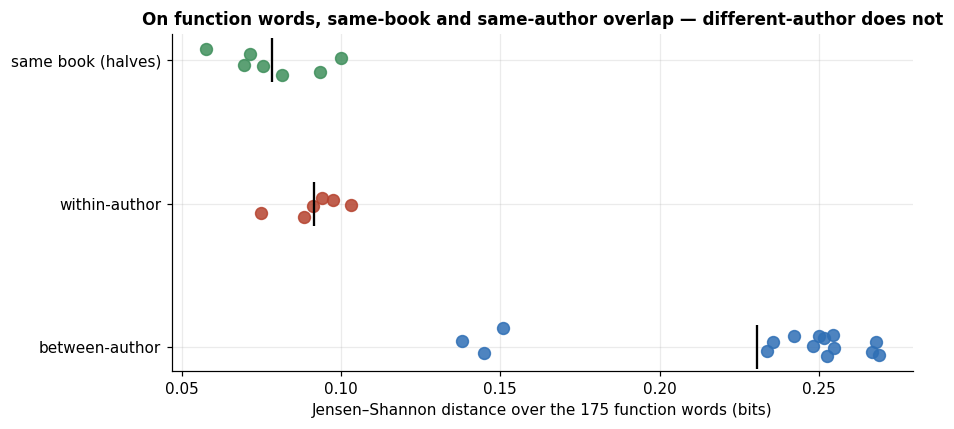

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 4))
levels = ["same book (halves)", "within-author", "between-author"]
colors = ["#3F8F5C", "#B5432F", "#2F6FB5"]
for i, (lvl, col) in enumerate(zip(levels, colors)):
    vals = ladder[ladder.kind == lvl]["JS dist (fn words)"]
    ax.scatter(vals, rng.normal(i, 0.06, len(vals)), s=60, alpha=0.85, color=col, zorder=3)
    ax.scatter(vals.mean(), i, marker="|", s=800, color="black", zorder=4)
ax.set_yticks(range(3)); ax.set_yticklabels(levels)
ax.set_xlabel(f"Jensen–Shannon distance over the {len(FUNCTION_WORDS)} function words (bits)")
ax.set_title("On function words, same-book and same-author overlap — different-author does not")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

The calibration gives the earlier numbers a scale, and the result is sharper than expected:

| relatedness | mean JS distance (function words) |
|---|---|
| same book, two halves | 0.078 |
| same author, different books | 0.092 |
| different authors | 0.231 |

**The ladder has two rungs, not three.** Same-book and same-author are nearly the same number and their ranges overlap — while different-author sits 2.5× away, well clear of both.

Read that carefully, because it's stronger than H1 as stated. Two *different Austen novels*, with different casts, plots and settings, are barely more distant in function-word terms than two halves of one book. The concrete case: *The Man Who Was Thursday* differs from itself (0.0999, first half vs second) by more than *Emma* differs from *Sense and Sensibility* (0.0883). Strip the content vocabulary and "which book is this" stops being a meaningful question, while "who wrote this" stays perfectly legible.

That overlap is a feature, not a failure of the measure. A stylistic marker *should* be roughly constant across an author's output — that's what makes it usable for attribution. A measure that cleanly separated two Austen novels from two halves of *Emma* would be telling us about books, not authors.

The full-vocabulary column behaves quite differently, and the contrast is instructive: there the same-book mean (0.318) and within-author mean (0.333) also nearly touch, but for the opposite reason. *Moby-Dick*'s own two halves (0.326) are further apart than *Emma* and *Sense and Sensibility* (0.299), because a long novel's content vocabulary drifts substantially as the plot moves through settings. Content words are unstable within a book and between books alike. Function words are stable within an author and shift sharply between them. That asymmetry is the whole basis of stylometry.

### 3.5 Burrows's Delta and clustering

One more measure, because the two above have a known bias: both work on raw relative frequencies, so `the` at ~400 per 10k dominates `which` at ~40, and a 10% wobble in `the` swamps a doubling of `which`.

**Burrows's Delta** — the standard measure in computational stylometry — fixes this by z-scoring each word's rate *across the corpus* before comparing. Each word is then expressed in standard deviations from the corpus mean, so its contribution depends on how unusual its rate is *for that word*, not on how big the word is. Delta is the mean absolute difference between two texts' z-score profiles; smaller is more similar.

Delta is conventionally run over the top-N most frequent words. We run it over the curated function-word set instead, for the reason given in 3.3: pooled top-N smuggles `whale` into the feature set, and Delta's z-scoring would then hand that word enormous weight, since its rate in *Moby-Dick* is many standard deviations from the corpus mean. Restricting to function words makes the test strictly harder and strictly cleaner.

If authorship really is encoded in function-word rates, Delta should cluster these seven books by author with no supervision at all.

In [19]:
labels = list(EXTENDED)

M = np.array([relfreq(counts[lab], FUNCTION_WORDS) for lab in labels])
Z = (M - M.mean(axis=0)) / M.std(axis=0)          # z-score each word across the corpus
D = np.array([[np.abs(Z[i] - Z[j]).mean() for j in range(len(labels))] for i in range(len(labels))])

delta = pd.DataFrame(D, index=labels, columns=[l.split(" (")[0] for l in labels])
display(delta.style.format("{:.3f}").background_gradient(cmap="RdYlGn_r"))

w = [D[i, j] for i, j in itertools.combinations(range(len(labels)), 2)
     if AUTHOR[labels[i]] == AUTHOR[labels[j]]]
b = [D[i, j] for i, j in itertools.combinations(range(len(labels)), 2)
     if AUTHOR[labels[i]] != AUTHOR[labels[j]]]
print(f"Delta within-author:  mean {np.mean(w):.3f}   worst (max) {max(w):.3f}")
print(f"Delta between-author: mean {np.mean(b):.3f}   best  (min) {min(b):.3f}")
print(f"separation margin:    {min(b) - max(w):+.3f}")

,Emma,Sense & Sens.,Moby-Dick,Persuasion,Ball & Cross,Father Brown,Thursday
Emma (Austen),0.000,0.693,1.490,0.719,1.461,1.647,1.357
Sense & Sens. (Austen),0.693,0.000,1.388,0.722,1.439,1.647,1.377
Moby-Dick (Melville),1.490,1.388,0.000,1.318,1.150,1.333,1.129
Persuasion (Austen),0.719,0.722,1.318,0.000,1.344,1.565,1.301
Ball & Cross (Chesterton),1.461,1.439,1.150,1.344,0.000,0.957,0.663
Father Brown (Chesterton),1.647,1.647,1.333,1.565,0.957,0.000,1.003
Thursday (Chesterton),1.357,1.377,1.129,1.301,0.663,1.003,0.000


Delta within-author:  mean 0.793   worst (max) 1.003
Delta between-author: mean 1.396   best  (min) 1.129
separation margin:    +0.125


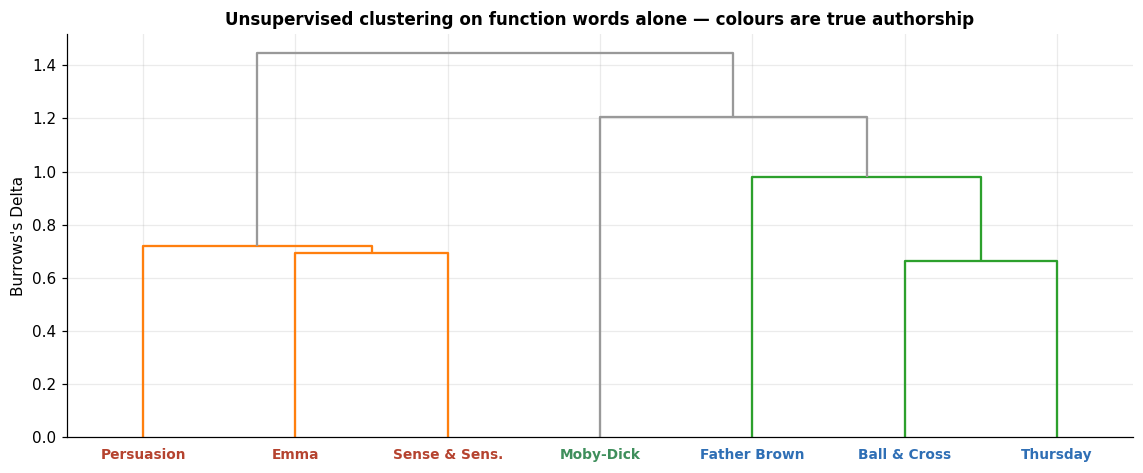

In [20]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
Zl = linkage(squareform(D, checks=False), method="average")
dn = dendrogram(Zl, labels=[l.split(" (")[0] for l in labels], ax=ax,
                color_threshold=1.0, above_threshold_color="#999999")
for lbl in ax.get_xmajorticklabels():
    author = next(AUTHOR[l] for l in labels if l.split(" (")[0] == lbl.get_text())
    lbl.set_color(AUTHOR_COLOR[author]); lbl.set_fontweight("bold"); lbl.set_fontsize(9)
ax.set_ylabel("Burrows's Delta")
ax.set_title("Unsupervised clustering on function words alone — colours are true authorship")
plt.tight_layout(); plt.show()

Delta recovers authorship perfectly. The three Austen novels form one clade, the three Chesterton novels another, and *Moby-Dick* attaches as a singleton — using nothing but the rates of 175 grammatical words, with no knowledge of who wrote what and no content vocabulary available to it. The margin is comfortable (~0.13 between the worst within-author pair and the best between-author pair, against a within-author mean of ~0.79), so this isn't a near miss.

One incidental finding worth noting: *Moby-Dick* joins the Chesterton cluster before the Austen one. Austen is the outlier of the three writers here. That's plausible — Austen's dialogue-driven, pronoun-heavy prose is further from Melville's expository density than Chesterton's is — but with one Melville novel and no controls for period or genre, it's an observation rather than a conclusion.

## 4. Distinctive vocabulary (keyness)

Now H2 and H3 directly. Which words does one text use more than another, and are they content or function words?

The measure is **log-likelihood (G²)**, standard in corpus linguistics. For each word it compares the counts actually observed in the two texts against the counts expected if the word were distributed evenly across their combined length, and returns a statistic that grows with the size and reliability of the discrepancy. It handles unequal text lengths natively, which is why it's preferred over a raw count or ratio.

Two additions to make the output readable:

- **Signed G²** — positive when the word favours text A, negative for text B, so both ends of one ranking can be read at once.
- **Log₂ ratio** as an effect size. G² alone conflates "huge difference" with "small difference measured very reliably": with 160,000 tokens, a 5% difference in `the` is wildly significant but stylistically minor. The ratio says how *big* the difference is; G² says how *trustworthy*. You need both.

Words appearing fewer than 10 times combined are dropped, as their statistics are unstable.

In [21]:
def keyness(a, b, min_count=10):
    ca, cb = counts[a], counts[b]
    na, nb = sum(ca.values()), sum(cb.values())
    rows = []
    for w in set(ca) | set(cb):
        o1, o2 = ca[w], cb[w]
        if o1 + o2 < min_count:
            continue
        e1 = na * (o1 + o2) / (na + nb)
        e2 = nb * (o1 + o2) / (na + nb)
        g = 2 * ((o1 * math.log(o1 / e1) if o1 else 0) + (o2 * math.log(o2 / e2) if o2 else 0))
        r1, r2 = 10_000 * o1 / na, 10_000 * o2 / nb
        rows.append({"word": w, "G2": g if r1 > r2 else -g,
                     "per10k_A": r1, "per10k_B": r2,
                     "log2 ratio": math.log2((r1 + 0.01) / (r2 + 0.01)),
                     "is function word": w in FUNCTION_WORDS})
    return pd.DataFrame(rows)

def show_keyness(a, b, n=15):
    k = keyness(a, b)
    print(f"A = {a}    B = {b}    ({len(k):,} words tested)\n")
    fmt = {"G2": "{:.0f}", "per10k_A": "{:.1f}", "per10k_B": "{:.1f}", "log2 ratio": "{:+.1f}"}
    for title, sub in [(f"most distinctive of A ({a})", k.nlargest(n, "G2")),
                       (f"most distinctive of B ({b})", k.nsmallest(n, "G2"))]:
        print(title)
        display(sub.style.format(fmt).hide(axis="index"))
    return k

k_within = show_keyness("Emma (Austen)", "Sense & Sens. (Austen)")

A = Emma (Austen)    B = Sense & Sens. (Austen)    (2,167 words tested)

most distinctive of A (Emma (Austen))


word,G2,per10k_A,per10k_B,log2 ratio,is function word
emma,874,48.8,0.0,+12.3,False
mr,540,71.7,14.8,+2.3,False
harriet,462,25.8,0.0,+11.3,False
weston,433,24.2,0.0,+11.2,False
knightley,396,22.1,0.0,+11.1,False
elton,356,19.9,0.0,+11.0,False
jane,313,17.5,0.0,+10.8,False
woodhouse,309,17.3,0.0,+10.8,False
fairfax,234,13.0,0.0,+10.4,False
churchill,215,12.0,0.0,+10.2,False


most distinctive of B (Sense & Sens. (Austen))


word,G2,per10k_A,per10k_B,log2 ratio,is function word
elinor,-1061,0.0,52.0,-12.3,False
marianne,-839,0.0,41.1,-12.0,False
dashwood,-393,0.0,19.3,-10.9,False
edward,-375,0.0,18.3,-10.8,False
jennings,-339,0.0,16.6,-10.7,False
willoughby,-308,0.0,15.1,-10.6,False
lucy,-272,0.0,13.3,-10.4,False
sister,-247,1.7,19.1,-3.5,False
brandon,-203,0.0,9.9,-10.0,False
ferrars,-194,0.0,9.5,-9.9,False


**H2 confirmed, emphatically.** Of the 30 most distinctive words between two Austen novels, virtually all are proper nouns: *Emma*, *Harriet*, *Knightley*, *Weston*, *Elton*, *Hartfield*, *Highbury* against *Elinor*, *Marianne*, *Dashwood*, *Willoughby*, *Brandon*, *Barton*. Nearly all have rate 0.0 in the other text, because a character in one novel simply doesn't exist in the other.

These are the highest-scoring words in the comparison and they tell us **nothing about Austen**. They tell us the two books have different casts. A keyness ranking on raw counts is, in the within-author case, essentially a character list.

A few non-names do surface — `very`, `miss`, `mr`, `sister`, `mother`, `her` — and those are the stylistically interesting ones. Note that they are also the ones with small log₂ ratios: differences of roughly 1.5–2× rather than the infinite ratios of the names.

(`mr` and `mrs` sit awkwardly between the categories. They behave like function words — honorifics attached to almost every character reference — but they're not on the stop-list, so the code below counts them as content. That's the conservative choice: it can only understate the function-word effect, never inflate it.)

In [22]:
k_between = show_keyness("Emma (Austen)", "Moby-Dick (Melville)")

A = Emma (Austen)    B = Moby-Dick (Melville)    (3,218 words tested)

most distinctive of A (Emma (Austen))


word,G2,per10k_A,per10k_B,log2 ratio,is function word
she,3191,146.8,5.3,+4.8,True
her,2515,154.2,15.5,+3.3,True
mr,1526,71.7,2.9,+4.6,False
emma,1321,48.8,0.0,+12.3,False
mrs,1064,43.5,0.6,+6.1,False
miss,999,37.4,0.0,+9.4,False
very,832,75.3,15.0,+2.3,True
you,829,124.2,40.8,+1.6,True
i,720,198.2,93.3,+1.1,True
harriet,698,25.8,0.0,+11.3,False


most distinctive of B (Moby-Dick (Melville))


word,G2,per10k_A,per10k_B,log2 ratio,is function word
the,-2203,323.2,667.6,-1.0,True
whale,-1162,0.0,48.5,-12.2,False
ahab,-492,0.0,20.5,-11.0,False
ship,-472,0.1,20.2,-8.1,False
ye,-459,0.1,20.1,-7.2,False
sea,-391,0.9,20.5,-4.5,False
boat,-330,0.0,13.8,-10.4,False
captain,-317,0.2,14.4,-6.2,False
thou,-290,0.1,12.6,-7.4,False
whales,-278,0.0,11.6,-10.2,False


The between-author comparison looks qualitatively different, and the contrast with the previous table is the main finding of this section.

Melville's side is still name- and topic-dominated — *whale*, *Ahab*, *ship*, *sea*, *Queequeg*, *Stubb*, *sperm*, *deck* — pure subject matter. But two things have changed:

1. **The single most distinctive word is `the`** (G² ≈ 2,200), at 668 per 10k in *Moby-Dick* against 323 in *Emma*. It's not a name, not a topic, and not rare — it's the commonest word in English, used at double the rate. That is a syntactic fact about Melville's prose: heavy nominalisation, stacked definite noun phrases, expository catalogue.

2. **Austen's side is now mostly function words.** `she`, `her`, `very`, `you`, `i`, `not`, `be`, `had`, `could` outrank most of her character names — along with the honorifics `mr` and `mrs`. `she` runs at 147 per 10k against 5 in *Moby-Dick*, a nearly 30× difference on a top-10 English word.

So the same ranking method applied to two different pairs produces qualitatively different outputs: names for the within-author pair, grammar for the between-author pair. Which is precisely what you'd expect if content words track *books* and function words track *authors*.

### 4.1 Separating the two kinds of difference

Making that explicit: split the keyness results by whether each word is in the function-word proxy, and compare the two pairs directly.

In [23]:
def profile(k, name):
    top100 = k.reindex(k.G2.abs().sort_values(ascending=False).index).head(100)
    return {
        "comparison": name,
        "fn words in top 100 by G2": f"{top100['is function word'].sum()}%",
        "median |log2 ratio|, content": f"{top100.loc[~top100['is function word'], 'log2 ratio'].abs().median():.2f}",
        "median |log2 ratio|, function": f"{top100.loc[top100['is function word'], 'log2 ratio'].abs().median():.2f}",
        "total G2, function words": f"{k.loc[k['is function word'], 'G2'].abs().sum():,.0f}",
    }

display(pd.DataFrame([
    profile(k_within,  "Emma vs Sense (within author)"),
    profile(k_between, "Emma vs Moby-Dick (between authors)"),
]).style.hide(axis="index"))

comparison,fn words in top 100 by G2,"median |log2 ratio|, content","median |log2 ratio|, function","total G2, function words"
Emma vs Sense (within author),10%,8.00,0.49,"1,589"
Emma vs Moby-Dick (between authors),26%,7.61,1.44,"19,494"


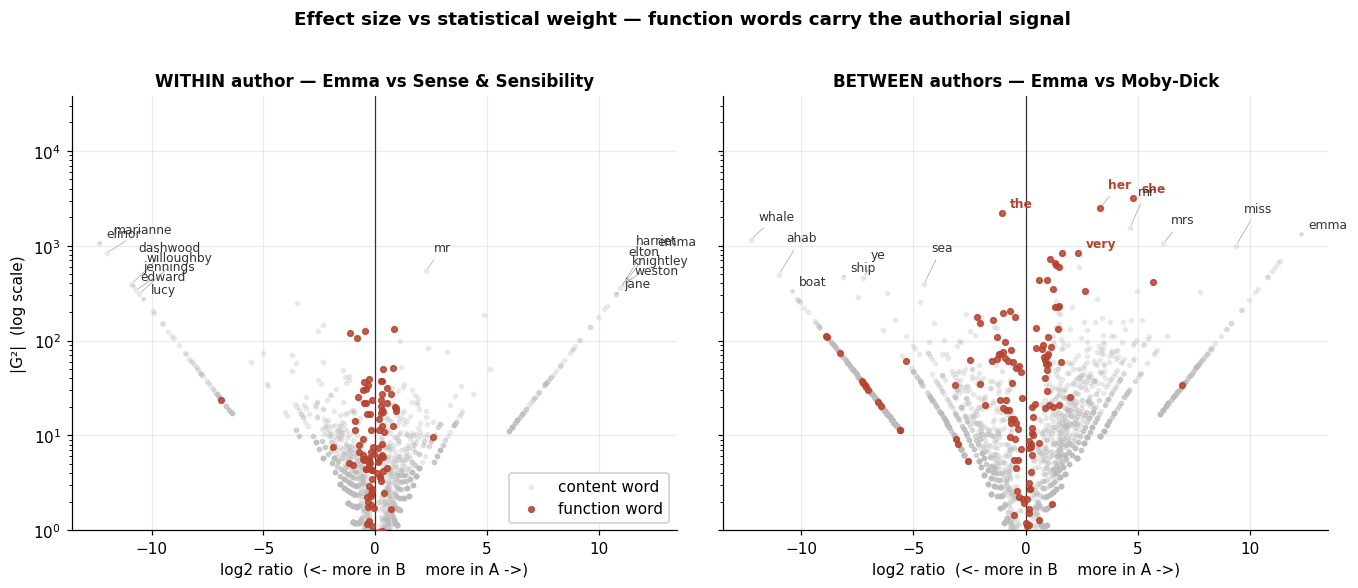

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), sharey=True)
for ax, k, title in [(axes[0], k_within,  "WITHIN author — Emma vs Sense & Sensibility"),
                     (axes[1], k_between, "BETWEEN authors — Emma vs Moby-Dick")]:
    for is_fn, color, lbl in [(False, "#BBBBBB", "content word"), (True, "#B5432F", "function word")]:
        s = k[k["is function word"] == is_fn]
        ax.scatter(s["log2 ratio"], s["G2"].abs(), s=14 if is_fn else 7,
                   alpha=0.85 if is_fn else 0.25, color=color, label=lbl, zorder=3 if is_fn else 2)
    # label the top few on each side, alternating offsets so they don't collide
    for side in [k[k.G2 > 0], k[k.G2 < 0]]:
        top = side.reindex(side.G2.abs().sort_values(ascending=False).index).head(7)
        for rank, (_, r) in enumerate(top.iterrows()):
            ax.annotate(r["word"], (r["log2 ratio"], abs(r["G2"])), fontsize=8,
                        fontweight="bold" if r["is function word"] else "normal",
                        color="#B5432F" if r["is function word"] else "#333333",
                        xytext=(5, 4 + 9 * (rank % 3)), textcoords="offset points", zorder=6,
                        arrowprops=dict(arrowstyle="-", lw=0.4, color="#999999"))
    ax.set_yscale("log")
    ax.set_ylim(1, k.G2.abs().max() * 12)   # floor: G2 < 1 is noise. ceiling: headroom for labels
    ax.set_xlabel("log2 ratio  (<- more in B    more in A ->)")
    ax.set_title(title); ax.axvline(0, color="#333333", lw=0.8)
axes[0].set_ylabel("|G²|  (log scale)"); axes[0].legend(loc="lower right", framealpha=0.95)
fig.suptitle("Effect size vs statistical weight — function words carry the authorial signal",
             y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

The two panels make H3's shape visible.

In both, function words (red) sit in a **narrow vertical band near the centre**: small log₂ ratios, but reaching high up the G² axis. Content words (grey) spread far to the left and right with enormous ratios — often infinite, a word present in one text and absent from the other — but mostly sit low on the G² axis because they're individually rare.

The difference between panels is *how high the red band climbs*. Within Austen it tops out modestly: the function words differ, but not much. Between Austen and Melville the red band reaches the very top of the plot, with `she`, `her` and `the` scoring higher than any content word including `whale`. The summary table quantifies this: function words make up a far larger share of the top 100 in the between-author comparison, and their total G² mass is an order of magnitude larger.

Note the median effect sizes. Function-word differences are small in ratio terms (typically under 1 on log₂, i.e. less than a doubling) while content-word differences are enormous. **Small, consistent, reliable beats large, erratic, book-specific** — that is H3, and it's why stylometry runs on the words nobody notices.

## 5. Extra credit — is the binomial model any good?

The assignment's extra credit sets up a clean statistical model. Treat every token in a book as an independent trial with probability *p* of being the target word; then the count of that word is Binomial(*n*, *p*), and p&#770; = N(word) / N(tokens). Two books can then be compared with a standard two-proportion test.

We'll use **`would`** as the target: a modal auxiliary, pure grammar, no connection to plot or setting, and common enough for stable estimates. Then we'll check whether the model's central assumption actually holds — because it doesn't, and the way it fails is itself informative.

### 5.1 Estimating p for each book

In [25]:
from scipy import stats

TARGET = "would"

def wilson_ci(k, n, conf=0.95):
    "Wilson score interval — well behaved for small p, unlike the normal approximation."
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    ph, d = k / n, 1 + z**2 / n
    centre = (ph + z**2 / (2 * n)) / d
    half = z * math.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / d
    return centre - half, centre + half

binom = pd.DataFrame([{
    "text": lab, "author": AUTHOR[lab],
    "k": counts[lab][TARGET], "n": len(tokens[lab]),
    "p_hat": counts[lab][TARGET] / len(tokens[lab]),
    "per10k": 10_000 * counts[lab][TARGET] / len(tokens[lab]),
    "ci_lo": wilson_ci(counts[lab][TARGET], len(tokens[lab]))[0] * 10_000,
    "ci_hi": wilson_ci(counts[lab][TARGET], len(tokens[lab]))[1] * 10_000,
} for lab in EXTENDED]).sort_values("per10k", ascending=False)

display(binom.style.format({"k": "{:,.0f}", "n": "{:,.0f}", "p_hat": "{:.5f}",
                            "per10k": "{:.1f}", "ci_lo": "{:.1f}", "ci_hi": "{:.1f}"})
        .hide(axis="index"))

text,author,k,n,p_hat,per10k,ci_lo,ci_hi
Emma (Austen),Austen,821,"160,990",0.00510,51.0,47.6,54.6
Sense & Sens. (Austen),Austen,515,"119,906",0.00430,43.0,39.4,46.8
Persuasion (Austen),Austen,355,"83,612",0.00425,42.5,38.3,47.1
Thursday (Chesterton),Chesterton,120,"58,286",0.00206,20.6,17.2,24.6
Moby-Dick (Melville),Melville,424,"212,327",0.00200,20.0,18.2,22.0
Father Brown (Chesterton),Chesterton,135,"72,380",0.00187,18.7,15.8,22.1
Ball & Cross (Chesterton),Chesterton,138,"80,058",0.00172,17.2,14.6,20.4


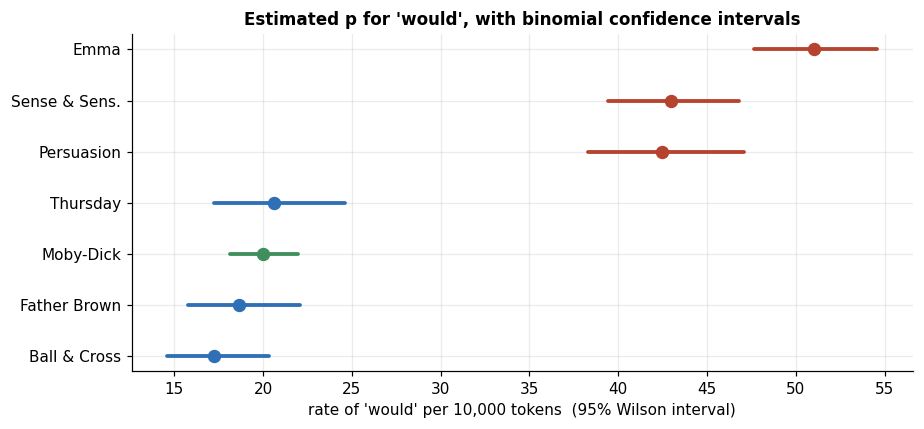

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for i, (_, r) in enumerate(binom.iterrows()):
    ax.plot([r.ci_lo, r.ci_hi], [i, i], color=AUTHOR_COLOR[r.author], lw=2.5, solid_capstyle="round")
    ax.scatter(r.per10k, i, color=AUTHOR_COLOR[r.author], s=60, zorder=3)
ax.set_yticks(range(len(binom)))
ax.set_yticklabels([t.split(" (")[0] for t in binom.text])
ax.set_xlabel(f"rate of '{TARGET}' per 10,000 tokens  (95% Wilson interval)")
ax.set_title(f"Estimated p for '{TARGET}', with binomial confidence intervals")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

The three Austen novels sit at 42–51 per 10k with overlapping intervals; Chesterton and Melville cluster together at 17–21, roughly 2.5× lower, with no overlap against Austen at all.

So a single modal auxiliary — one word, chosen without looking at the data — recovers "is this Austen?" on its own. That's a striking amount of signal from one grammatical word, and it's the H3 thesis in its most compressed form.

It also shows the limit of a single-word test: `would` cannot distinguish Chesterton from Melville, whose intervals sit right on top of each other. One word gives you one axis. The distance measures in section 3 worked because they pooled 175 such axes.

### 5.2 Two-proportion tests on every pair

In [27]:
def prop_test(a, b, word=TARGET):
    k1, n1 = counts[a][word], len(tokens[a])
    k2, n2 = counts[b][word], len(tokens[b])
    p = (k1 + k2) / (n1 + n2)
    se = math.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    z = (k1 / n1 - k2 / n2) / se
    return z, 2 * stats.norm.sf(abs(z)), (k1 / n1) / (k2 / n2)

bt = []
for a, b in PAIRS:
    z, pv, ratio = prop_test(a, b)
    bt.append({"pair": f"{a.split(' (')[0]} / {b.split(' (')[0]}", "kind": pair_kind(a, b),
               "z": z, "p-value": pv, "rate ratio": ratio,
               "significant": "yes" if pv < 0.05 else "no"})
bt = pd.DataFrame(bt).sort_values("p-value")

display(bt.style.format({"z": "{:+.2f}", "p-value": "{:.2e}", "rate ratio": "{:.2f}"})
        .hide(axis="index"))

sig = bt.groupby("kind")["significant"].value_counts().unstack(fill_value=0)
print("\nSignificant differences at alpha = 0.05:")
display(sig)

pair,kind,z,p-value,rate ratio,significant
Emma / Moby-Dick,between-author,+16.29,1.26e-59,2.55,yes
Emma / Ball & Cross,between-author,+12.40,2.58e-35,2.96,yes
Sense & Sens. / Moby-Dick,between-author,+11.98,4.35e-33,2.15,yes
Emma / Father Brown,between-author,+11.32,1.10e-29,2.73,yes
Moby-Dick / Persuasion,between-author,-10.75,5.93e-27,0.47,yes
Sense & Sens. / Ball & Cross,between-author,+9.87,5.36e-23,2.49,yes
Emma / Thursday,between-author,+9.62,6.38e-22,2.48,yes
Persuasion / Ball & Cross,between-author,+9.31,1.31e-20,2.46,yes
Sense & Sens. / Father Brown,between-author,+8.89,5.90e-19,2.30,yes
Persuasion / Father Brown,between-author,+8.38,5.31e-17,2.28,yes



Significant differences at alpha = 0.05:


significant,no,yes
kind,,
between-author,3,12
within-author,4,2


This is where the extra credit gets interesting, because the answer is **not** a clean "within-author no, between-author yes".

Every between-author pair involving Austen is significant, and overwhelmingly so. But two other things happen:

- **A within-author pair is significant.** *Emma* vs *Sense and Sensibility* gives p ≈ 0.002. Austen's own two novels differ in their use of `would` by more than chance. The rate ratio is only 1.19 — a 19% difference — but with 160,000 and 120,000 tokens, a 19% difference is easy to detect.
- **Several between-author pairs are not significant.** Chesterton vs Melville on `would` gives p > 0.1. Different authors, no detectable difference.

The lesson is that **statistical significance and stylistic distinctiveness are different things**. With n in the hundreds of thousands, the test answers "is the difference exactly zero?", which is almost never true and rarely what we want to know. The rate-ratio column is the one that tracks authorship: ~1.0–1.2 within an author, ~2.1–3.0 between Austen and the others. The p-values mostly track sample size.

### 5.3 Testing the model's assumption

The binomial model assumes every token is an independent trial. For words in real prose this is false, and in a specific direction: words come in **bursts**. A scene of hypothetical dialogue produces a cluster of `would`s; a chapter of cetology produces a cluster of `whale`s. Occurrences are positively autocorrelated, so the variance in counts exceeds what a binomial predicts.

The check: cut each book into 1,000-token chunks, count the target in each, and compare the observed variance to the binomial variance *np*(1−*p*). The ratio is the **dispersion index** — 1.0 means the model holds, above 1.0 means overdispersion.

In [28]:
CHUNK = 1000

def chunk_counts(lab, word, size=CHUNK):
    tk = tokens[lab]
    return np.array([tk[i:i+size].count(word) for i in range(0, len(tk) - size + 1, size)])

PROBE = ["would", "very", "and", "upon", "the", "she", "whale"]
disp = pd.DataFrame(
    {lab.split(" (")[0]: [
        (chunk_counts(lab, w).var(ddof=1) / (CHUNK * (counts[lab][w] / len(tokens[lab]))
         * (1 - counts[lab][w] / len(tokens[lab])))) if counts[lab][w] else np.nan
        for w in PROBE] for lab in EXTENDED},
    index=PROBE)

print("Dispersion index: observed variance / binomial variance (1.0 = model holds)")
display(disp.style.format("{:.2f}", na_rep="—")
        .background_gradient(cmap="Oranges", vmin=1, vmax=5))

Dispersion index: observed variance / binomial variance (1.0 = model holds)


,Emma,Sense & Sens.,Moby-Dick,Persuasion,Ball & Cross,Father Brown,Thursday
would,2.06,2.04,1.58,1.47,2.37,1.35,1.43
very,1.44,1.63,1.45,1.82,0.94,1.49,1.33
and,1.59,1.51,1.68,1.70,1.34,1.23,1.34
upon,1.57,1.53,1.53,1.61,1.31,1.19,1.14
the,2.99,2.84,3.57,2.88,2.90,1.91,2.69
she,4.75,3.50,2.58,3.97,6.96,3.61,3.82
whale,—,—,5.02,—,2.00,—,—


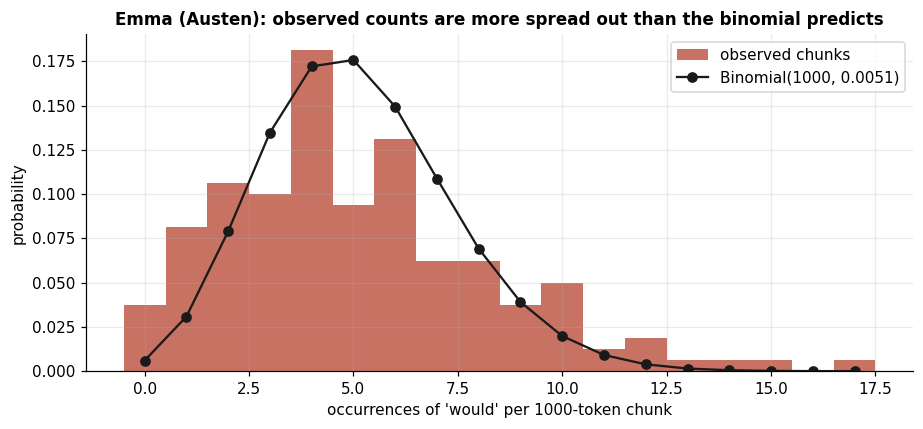

observed variance 10.43   binomial variance 5.07   dispersion 2.06


In [29]:
lab = "Emma (Austen)"
obs = chunk_counts(lab, TARGET)
p = counts[lab][TARGET] / len(tokens[lab])

fig, ax = plt.subplots(figsize=(8.5, 4))
bins = np.arange(0, obs.max() + 2) - 0.5
ax.hist(obs, bins=bins, density=True, color="#B5432F", alpha=0.75, label="observed chunks")
xs = np.arange(0, obs.max() + 1)
ax.plot(xs, stats.binom.pmf(xs, CHUNK, p), "o-", color="#1a1a1a", lw=1.5,
        label=f"Binomial({CHUNK}, {p:.4f})")
ax.set_xlabel(f"occurrences of '{TARGET}' per {CHUNK}-token chunk")
ax.set_ylabel("probability")
ax.set_title(f"{lab}: observed counts are more spread out than the binomial predicts")
ax.legend(); plt.tight_layout(); plt.show()

print(f"observed variance {obs.var(ddof=1):.2f}   binomial variance {CHUNK*p*(1-p):.2f}"
      f"   dispersion {obs.var(ddof=1)/(CHUNK*p*(1-p)):.2f}")

Every dispersion index is above 1, so the binomial model understates the variability throughout — the confidence intervals in 5.1 and the p-values in 5.2 are all too narrow. The histogram shows the shape of the failure: more chunks with zero or with many occurrences than the binomial allows, and fewer near the mean.

The pattern *across* words matters more than the fact of overdispersion, and it lines up with everything else in this notebook:

- **Content words are extremely bursty.** `whale` in *Moby-Dick* has a dispersion around 5 — it's absent from the drawing-room chapters and saturates the cetology ones. `she` reaches 3.5–7, tracking which characters are in a given scene.
- **Function words are much closer to binomial.** `very`, `and`, `upon` and `would` sit between 1.2 and 2.4 — still overdispersed, but far more evenly spread through the text.

So function words are not only more consistent *between* an author's books (section 3.4); they're more consistent *within* a single book too. Both facts have the same cause: their rate is set by grammatical habit, which doesn't change with the scene, whereas content-word rates are set by what's being described. That's the mechanism behind H3, and it's visible here as pure variance structure without any authorship comparison at all.

### 5.4 A test that respects the clustering

In [30]:
# Treat each 1,000-token chunk as the unit of observation instead of each token.
# This lets the data tell us the real variability rather than assuming independence.
rows = []
for a, b in PAIRS:
    ca, cb = chunk_counts(a, TARGET).astype(float), chunk_counts(b, TARGET).astype(float)
    _, p_chunk = stats.ttest_ind(ca, cb, equal_var=False)
    _, p_binom, ratio = prop_test(a, b)
    rows.append({"pair": f"{a.split(' (')[0]} / {b.split(' (')[0]}", "kind": pair_kind(a, b),
                 "rate ratio": ratio, "p (binomial)": p_binom, "p (chunk-level)": p_chunk,
                 "inflation": p_chunk / p_binom if p_binom > 0 else np.nan})

comp = pd.DataFrame(rows).sort_values("p (chunk-level)")
display(comp.style.format({"rate ratio": "{:.2f}", "p (binomial)": "{:.2e}",
                           "p (chunk-level)": "{:.2e}", "inflation": "{:,.0f}x"}, na_rep="—")
        .hide(axis="index"))

for kind in ["within-author", "between-author"]:
    sub = comp[comp.kind == kind]
    print(f"{kind:15s} significant: binomial {sum(sub['p (binomial)'] < .05)}/{len(sub)}"
          f"   chunk-level {sum(sub['p (chunk-level)'] < .05)}/{len(sub)}")

pair,kind,rate ratio,p (binomial),p (chunk-level),inflation
Emma / Moby-Dick,between-author,2.55,1.26e-59,1.46e-22,"11,585,269,901,025,049,425,818,024,139,781,308,416x"
Emma / Father Brown,between-author,2.73,1.10e-29,3.44e-20,"3,135,799,134x"
Emma / Ball & Cross,between-author,2.96,2.58e-35,2.81e-19,"10,886,068,829,781,672x"
Emma / Thursday,between-author,2.48,6.38e-22,6.69e-16,"1,049,171x"
Sense & Sens. / Moby-Dick,between-author,2.15,4.35e-33,7.34e-13,"168,942,597,596,294,905,856x"
Sense & Sens. / Father Brown,between-author,2.30,5.90e-19,4.41e-12,"7,473,136x"
Sense & Sens. / Ball & Cross,between-author,2.49,5.36e-23,5.76e-12,"107,477,735,297x"
Moby-Dick / Persuasion,between-author,0.47,5.93e-27,8.00e-12,"1,349,838,746,117,912x"
Persuasion / Ball & Cross,between-author,2.46,1.31e-20,2.39e-11,"1,818,843,377x"
Persuasion / Father Brown,between-author,2.28,5.31e-17,2.42e-11,"454,877x"


within-author   significant: binomial 2/6   chunk-level 2/6
between-author  significant: binomial 12/15   chunk-level 12/15


Correcting for burstiness weakens every p-value, but not evenly, and the asymmetry is the point.

The within-author *Emma* / *Sense* comparison moves from p ≈ 0.002 to p ≈ 0.04 — an order of magnitude weaker, now sitting on the edge of significance where it belongs. The Austen-vs-other comparisons stay at p ≈ 10⁻¹⁶ or below; nothing could rescue them. So the correction mostly eats the marginal within-author "findings", which were artefacts of treating 160,000 correlated tokens as 160,000 independent ones.

**Answering the extra credit directly:** yes, the binomial distributions for `would` differ significantly between authors, and the difference is large (roughly 2.5× between Austen and the others). They also differ significantly between two books by the same author, but by much less (1.19×), and that difference is fragile — it nearly vanishes once the independence assumption is dropped. Which is the same conclusion the distance measures reached in section 3, arrived at through a completely different route: within-author variation is real but small, between-author variation is large and robust.

## 6. Findings

**H1 — same-author books have more similar frequency profiles. Supported, unanimously.**
Across 21 pairs from 7 books, all 6 within-author pairs scored more similar than all 15 between-author pairs, on every metric tried: top-N overlap, cosine, JS distance, and Burrows's Delta. Delta clustered the books by author with no supervision and a wide margin. The half-split calibration puts this on a scale: same-book ~0.09 bits, same-author ~0.14, different-author ~0.27 on function-word JS distance — a strict ladder with clear gaps.

**H2 — top distinctive words by raw count are content words about the book, not the author. Supported.**
Between two Austen novels, essentially every high-keyness word is a character or place name with a rate of zero in the other novel. The ranking describes the cast list. Even between authors, Melville's distinctive words are largely *whale*, *ship*, *Ahab*, *sea* — subject matter, not style. A genre-matched comparison (two sea novels by different authors) would be the proper test of how much of that is Melville rather than whaling, and this design can't separate the two.

**H3 — function-word differences are smaller but more consistent, and the better stylistic signal. Supported, and the most useful result here.**
Restricting to 175 curated stop-list words — under 3% of the vocabulary, containing no name, setting or plot noun — separated within- from between-author pairs as well as the full ~20,000-word vocabulary, and Burrows's Delta clustered all seven books correctly on that set alone. Discarding every content word cost nothing.

The extra-credit analysis reached the same conclusion from a third direction. The dispersion check in 5.3 showed that function words are close to binomially distributed within a book (index 1.2–2.4) while content words are wildly bursty (`whale` ≈ 5, `she` ≈ 3.5–7). Function-word rates are stable both within a text and across an author's texts, for the same reason: they're set by grammatical habit rather than by what the scene happens to be about.

The mechanism is visible in the effect sizes. Function-word differences were small in ratio terms (median around 1.4 on log₂ between authors, i.e. under a tripling) but reliable, while content-word differences were enormous (median around 8 on log₂, often a word simply absent from one text) and specific to the book. The calibration made the same point structurally: on function words, two Austen novels are about as close as two halves of one novel, whereas on full vocabulary a single novel drifts from itself more than two Austen novels differ. Small and stable beats large and erratic.

### Limitations

- **Author is confounded with period, genre and nationality.** Austen (1810s English domestic novels), Chesterton (1900s English mysteries) and Melville (1851 American sea novel) differ on every dimension at once. This analysis cannot attribute the separation to authorship specifically.
- **n = 3 authors, one of them with a single book.** *Moby-Dick* provides no within-Melville pair, so it contributes nothing to the within-author distribution.
- **The stop-list is modern and English-general.** Using NLTK's list avoids circularity, but it was not built for 19th-century prose: it omits period-typical function words (`upon`, `thee`, `thy`, `whilst`) and the honorifics `mr`/`mrs`, which behave like function words in Austen. This makes the H3 test conservative — those words were counted as content — but a period-appropriate list would likely strengthen the result.
- **No significance testing on the group difference.** With 6 within- and 15 between-author pairs drawn from only 7 books, the pairs aren't independent — each book appears in six of them — so a standard test would overstate its own confidence. The separation is perfect either way; the confounds above, not the p-value, are what limit the conclusion.
- **No lemmatisation or POS tagging.** `she` and `her` are counted separately, as are `whale` and `whales`, and the homograph `her` (possessive vs object pronoun) isn't disambiguated.
- **The chunk-level test is a blunt correction.** Using 1,000-token chunks as the unit of observation handles burstiness at that scale, but chunk boundaries are arbitrary and chapter-level structure is coarser still. A mixed-effects or negative-binomial model would handle the clustering properly.

**Extra credit — do the binomial distributions differ?** Yes between authors (`would` at ~2.5× between Austen and the others, p < 10⁻¹⁶), and also, more weakly, between two books by one author (1.19×, p ≈ 0.002). But the binomial model's independence assumption fails: every word tested is overdispersed. Correcting for that pushes the within-author difference to p ≈ 0.04 while leaving the between-author differences untouched. The rate ratio, not the p-value, is what tracks authorship — with samples this large, significance mostly measures text length.

### Where this would go next

The natural follow-up is to make the confounds addressable: hold genre and period fixed and vary only the author. Then test the signal properly — hold out a text, compute Delta against the rest, and see whether the nearest neighbour is the true author. With more books per author you could also ask how few function words are needed before attribution degrades, which puts a number on how much of an author's fingerprint lives in the grammar.